In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras import layers, models
from sklearn.metrics import confusion_matrix, classification_report

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


In [3]:
from tensorflow.keras.datasets import fashion_mnist

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


In [4]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

print("Number of classes:", len(class_names))
print("Classes:", class_names)

Number of classes: 10
Classes: ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


In [5]:
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())
print("Image data type:", X_train.dtype)

Minimum pixel value: 0
Maximum pixel value: 255
Image data type: uint8


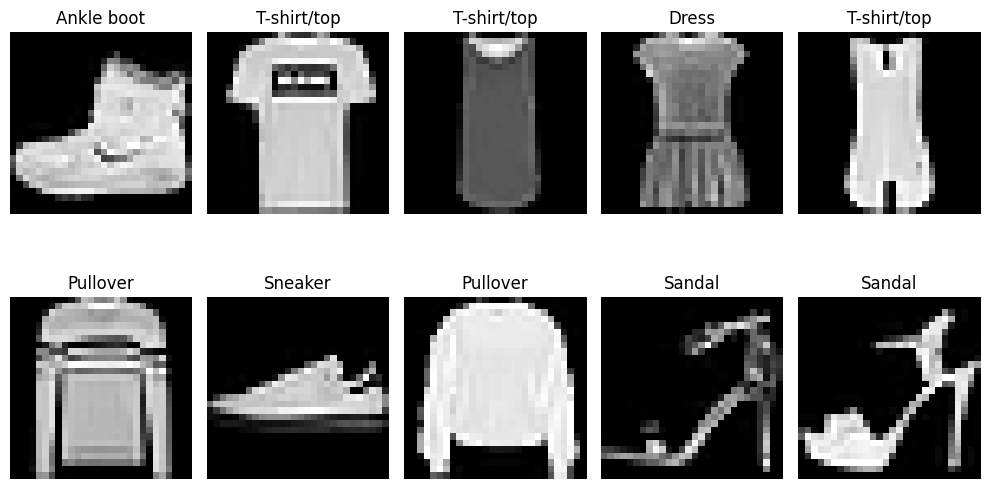

In [6]:
plt.figure(figsize=(10, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
unique, counts = np.unique(y_train, return_counts=True)

class_distribution = pd.DataFrame({
    "Class": [class_names[i] for i in unique],
    "Count": counts
})

print(class_distribution)

         Class  Count
0  T-shirt/top   6000
1      Trouser   6000
2     Pullover   6000
3        Dress   6000
4         Coat   6000
5       Sandal   6000
6        Shirt   6000
7      Sneaker   6000
8          Bag   6000
9   Ankle boot   6000


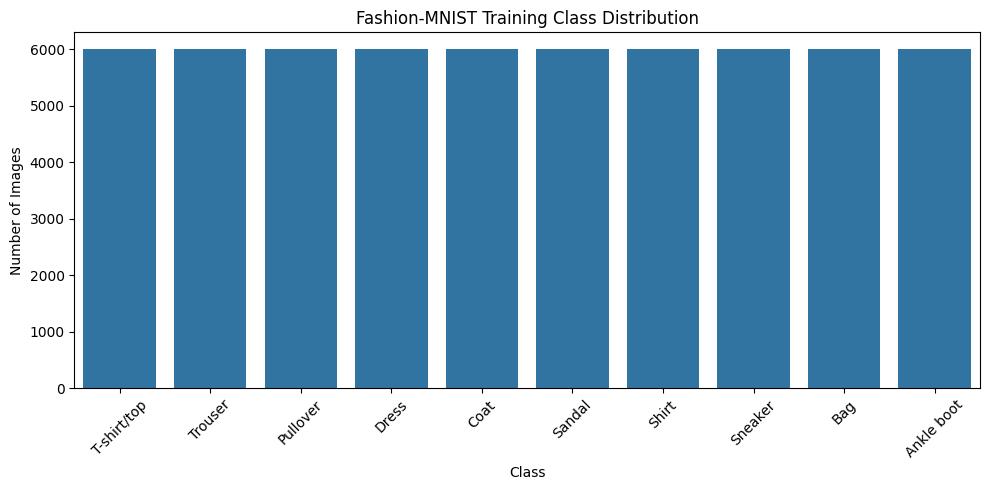

In [8]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=class_distribution,
    x="Class",
    y="Count"
)

plt.xticks(rotation=45)
plt.title("Fashion-MNIST Training Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

In [9]:
# Normalize pixel values from 0-255 to 0-1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Training pixel range:", X_train.min(), "to", X_train.max())
print("Testing pixel range:", X_test.min(), "to", X_test.max())

Training pixel range: 0.0 to 1.0
Testing pixel range: 0.0 to 1.0


In [10]:
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Training shape after reshaping:", X_train.shape)
print("Testing shape after reshaping:", X_test.shape)

Training shape after reshaping: (60000, 28, 28, 1)
Testing shape after reshaping: (10000, 28, 28, 1)


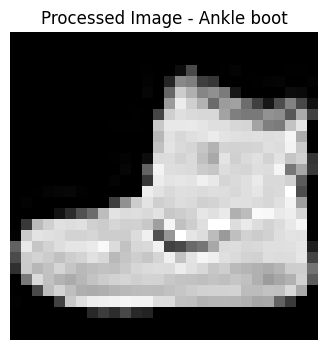

In [11]:
plt.figure(figsize=(4, 4))

plt.imshow(X_train[0].squeeze(), cmap="gray")
plt.title(f"Processed Image - {class_names[y_train[0]]}")
plt.axis("off")

plt.show()

In [12]:
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


In [14]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 50s 57ms/step - accuracy: 0.7980 - loss: 0.5591 - val_accuracy: 0.8665 - val_loss: 0.3635
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 47s 56ms/step - accuracy: 0.8681 - loss: 0.3641 - val_accuracy: 0.8718 - val_loss: 0.3339
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 80s 54ms/step - accuracy: 0.8850 - loss: 0.3144 - val_accuracy: 0.8867 - val_loss: 0.2973
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 49s 58ms/step - accuracy: 0.8941 - loss: 0.2878 - val_accuracy: 0.8882 - val_loss: 0.2876
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 79s 54ms/step - accuracy: 0.9017 - loss: 0.2641 - val_accuracy: 0.9028 - val_loss: 0.2593
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 84s 56ms/step - accuracy: 0.9088 - loss: 0.2455 - val_accuracy: 0.9062 - val_loss: 0.2561
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 47s 55ms/step - accuracy: 0.9161 - loss: 0.2256 - val_accuracy: 0.9090 - val_loss: 0.2440
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 50s 59ms/step - accuracy: 0.9205 - loss: 0.2125 - 

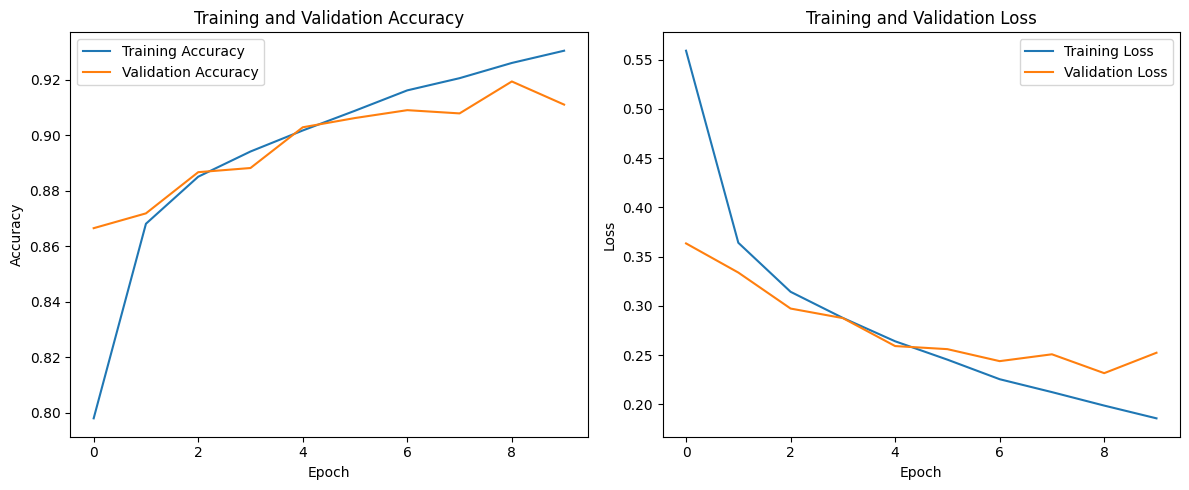

In [15]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [16]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - accuracy: 0.9051 - loss: 0.2652
Test Loss: 0.26520735025405884
Test Accuracy: 0.9050999879837036


In [17]:
y_pred_prob = model.predict(X_test)

y_pred = np.argmax(y_pred_prob, axis=1)

print("Prediction shape:", y_pred.shape)
print("First 20 predicted labels:", y_pred[:20])
print("First 20 actual labels:", y_test[:20])

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step
Prediction shape: (10000,)
First 20 predicted labels: [9 2 1 1 0 1 4 6 5 7 4 5 7 3 4 1 2 4 8 0]
First 20 actual labels: [9 2 1 1 6 1 4 6 5 7 4 5 7 3 4 1 2 4 8 0]


In [18]:
report = classification_report(
    y_test,
    y_pred,
    target_names=class_names
)

print(report)

              precision    recall  f1-score   support

 T-shirt/top       0.81      0.91      0.86      1000
     Trouser       0.99      0.98      0.99      1000
    Pullover       0.82      0.88      0.85      1000
       Dress       0.92      0.91      0.92      1000
        Coat       0.85      0.85      0.85      1000
      Sandal       0.98      0.97      0.98      1000
       Shirt       0.79      0.64      0.71      1000
     Sneaker       0.92      0.99      0.95      1000
         Bag       0.98      0.97      0.98      1000
  Ankle boot       0.99      0.94      0.96      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.90     10000
weighted avg       0.91      0.91      0.90     10000



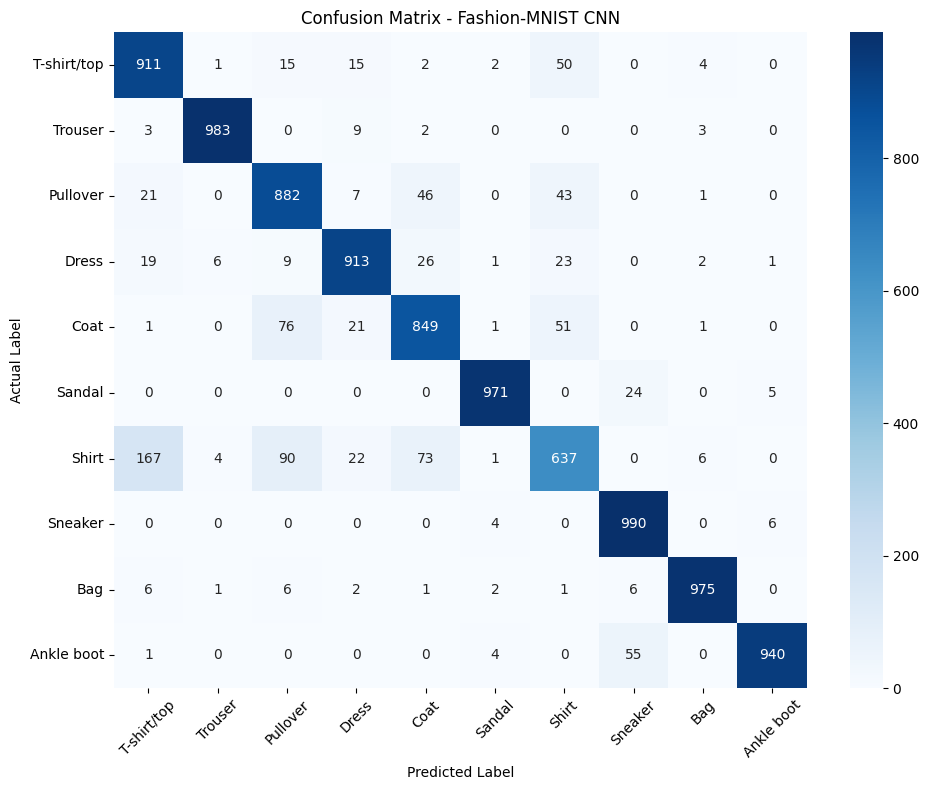

In [19]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Confusion Matrix - Fashion-MNIST CNN")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [20]:
correct_indices = np.where(y_pred == y_test)[0]
incorrect_indices = np.where(y_pred != y_test)[0]

print("Correct predictions:", len(correct_indices))
print("Incorrect predictions:", len(incorrect_indices))

Correct predictions: 9051
Incorrect predictions: 949


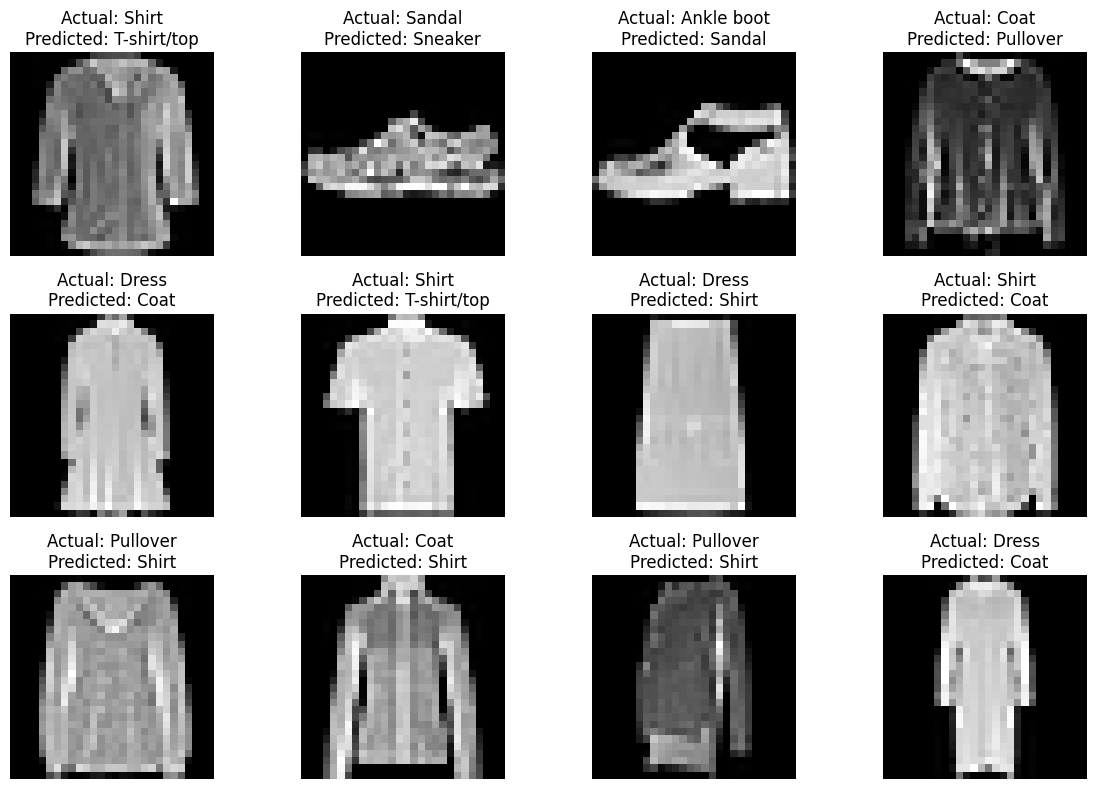

In [21]:
plt.figure(figsize=(12, 8))

for i, idx in enumerate(incorrect_indices[:12]):
    plt.subplot(3, 4, i + 1)
    plt.imshow(X_test[idx].squeeze(), cmap="gray")
    plt.title(
        f"Actual: {class_names[y_test[idx]]}\n"
        f"Predicted: {class_names[y_pred[idx]]}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [22]:
model.save("fashion_mnist_cnn.keras")

print("Model saved successfully.")

Model saved successfully.


In [23]:
import os

print("Model file exists:", os.path.exists("fashion_mnist_cnn.keras"))

Model file exists: True


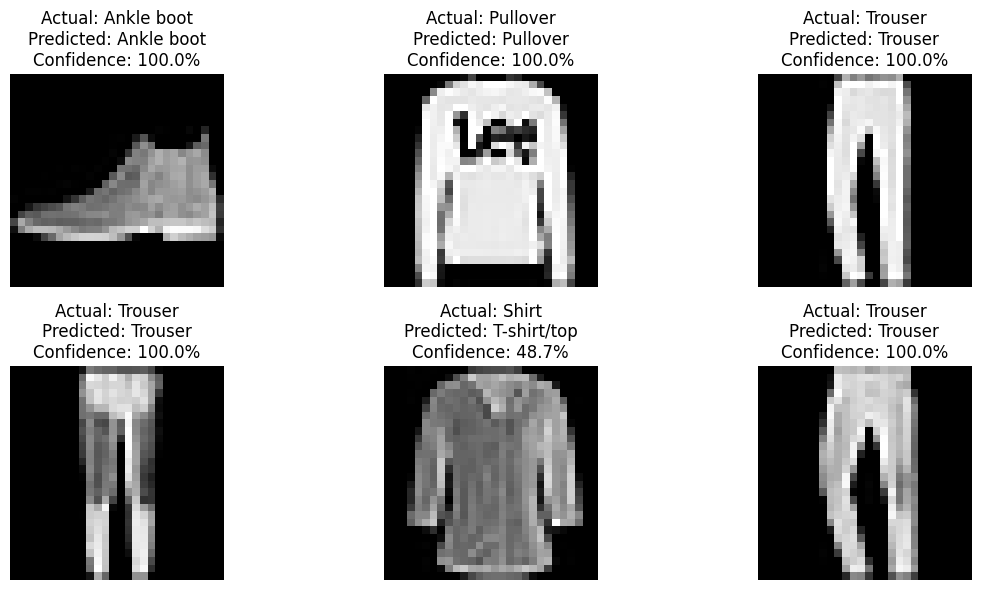

In [24]:
sample_indices = [0, 1, 2, 3, 4, 5]

plt.figure(figsize=(12, 6))

for i, idx in enumerate(sample_indices):
    confidence = np.max(y_pred_prob[idx]) * 100

    plt.subplot(2, 3, i + 1)
    plt.imshow(X_test[idx].squeeze(), cmap="gray")
    plt.title(
        f"Actual: {class_names[y_test[idx]]}\n"
        f"Predicted: {class_names[y_pred[idx]]}\n"
        f"Confidence: {confidence:.1f}%"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()